In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [20]:
def get_oil_data(fill_method = None):
    # Read raw oil data
    oil = pd.read_csv("DCOILWTICO.csv")

    # Format oil table columns and data types
    oil.columns = ["date", "wti_price"]

    oil["date"] = pd.to_datetime(oil["date"], errors="coerce")
    oil["wti_price"] = pd.to_numeric(oil["wti_price"], errors="coerce")

    oil = (
        oil.dropna(subset=["date"])
           .drop_duplicates(subset="date")
           .sort_values("date")
           .set_index("date")
    )

    if fill_method == "ffill":
        oil = oil.ffill()
    elif not fill_method:
        oil = oil.dropna(subset=["wti_price"])
    else:
        raise ValueError("fill_method must be 'ffill' or None")

    return oil

In [23]:
oil = get_oil_data(fill_method="ffill")

oil["daily return"] = oil['wti_price'].pct_change()
oil["cumulative return"] = (1 + oil["daily return"]).cumprod()

<Axes: title={'center': 'WTI Oil Cumulative Return'}, xlabel='date'>

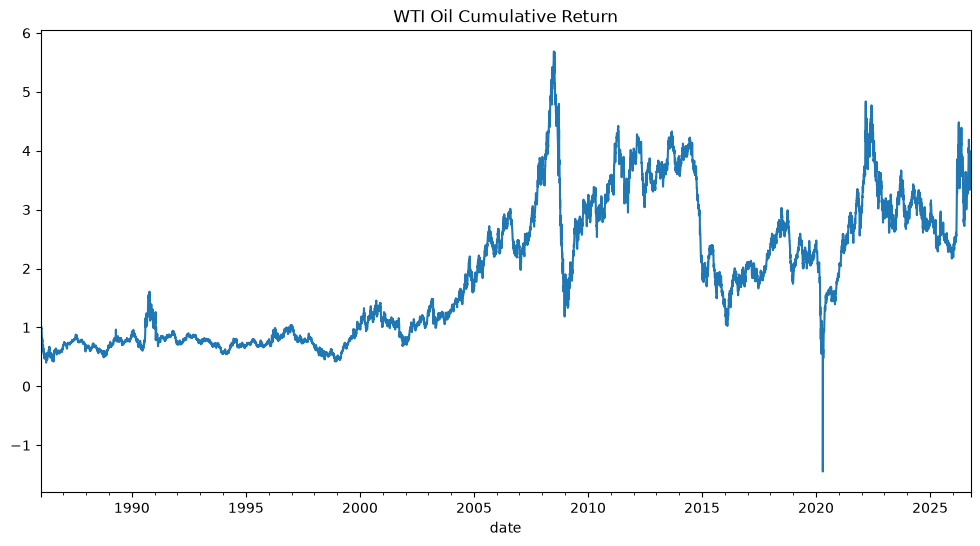

In [24]:
oil["cumulative return"].plot(title="WTI Oil Cumulative Return", figsize=(12, 6))

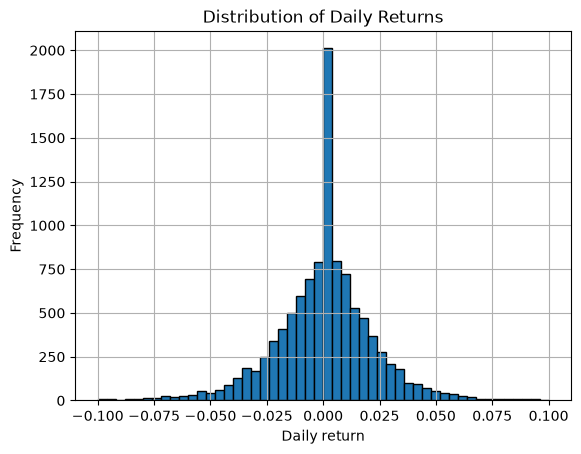

In [25]:
# Plot histogram of daily returns
oil["daily return"].dropna().hist(bins = 50, range = (-0.10, 0.10), edgecolor="black")

plt.xlabel("Daily return")
plt.ylabel("Frequency")
plt.title("Distribution of Daily Returns")
plt.show()

In [27]:
# Last available price in each week ending Friday
oil_weekly = oil[["wti_price"]].resample("W-FRI").last()

# Week-to-week return
oil_weekly["weekly return"] = (
    oil_weekly["wti_price"].pct_change(fill_method=None)
)

# Cumulative return since the first weekly price
oil_weekly["cumulative return"] = (
    (1 + oil_weekly["weekly return"]).cumprod() - 1
)

# Starting point has zero cumulative return
oil_weekly.iloc[0, oil_weekly.columns.get_loc("cumulative return")] = 0

In [28]:
oil_weekly

,wti_price,weekly return,cumulative return
date,,,
1986-01-03,26.00,NaN,0.000000
1986-01-10,25.65,-0.013462,-0.013462
1986-01-17,23.63,-0.078752,-0.091154
1986-01-24,19.45,-0.176894,-0.251923
1986-01-31,19.58,0.006684,-0.246923
...,...,...,...
2026-09-18,101.44,0.001679,2.901538
2026-09-25,85.23,-0.159799,2.278077
2026-10-02,97.89,0.148539,2.765000


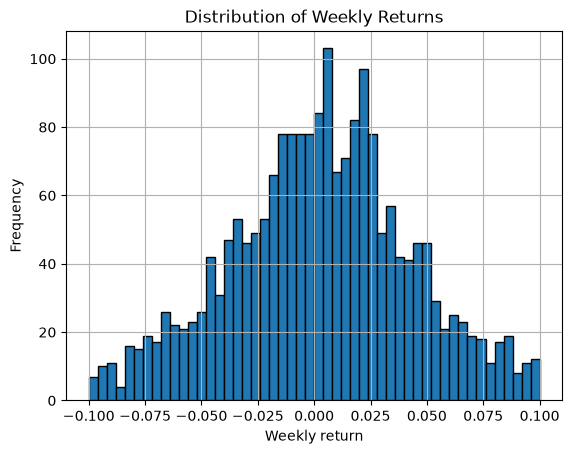

In [30]:
# Plot histogram of weekly returns
oil_weekly["weekly return"].dropna().hist(bins = 50, range = (-0.10, 0.10), edgecolor="black")

plt.xlabel("Weekly return")
plt.ylabel("Frequency")
plt.title("Distribution of Weekly Returns")
plt.show()